# E2 (Pro版)：多目标工程权衡 —— 动力性与经济性 Pareto 前沿萃取与膝点决策

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链3：整车能量管理与先进优化控制** 的高维设计决策实验。
> 在主机厂整车项目立项与总成匹配评审会上，产品经理渴望“零百加速闯进 4 秒”，财务总监紧咬“制造 BOM 成本必须压减 10%”，法规部门严卡“整车整备质量与能耗”。在真实的物理世界中，**没有任何一组单一设计参数能够同时满足所有指标的最优** —— 鱼和熊掌不可兼得的工程现实催生了**多目标优化 (Multi-Objective Optimization)**。主机厂工程师的现代正向设计范式，绝非拍脑袋试凑，而是借助快速非支配排序遗传算法（**NSGA-II**）在大规模决策空间中萃取出一整条 **Pareto 最优前沿 (Pareto Front)**，并利用归一化理想点法精准定位“性价比黄金拐点 —— **膝点 (Knee Point)**”。本实验基于工业级优化计算框架 **pymoo**，深入解构纯电动汽车电机额定功率与整备质量的双目标协同设计，掌握现代车企产品矩阵定义的底层工程决策科学。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & 多目标数学原理)**：执行阶段一，确认 `pymoo` 优化求解器就绪，掌握非支配支配关系（Dominance）、Pareto 前沿与黄金膝点（Knee Point）概念；
* **第二步 (整车动力学与制造成本建模)**：阶段二构建 $0-100\,\text{km/h}$ 零百加速时间（动力性）与三电制造 BOM 成本（经济性）的物理多目标数学模型；
* **第三步 (真机闭环 NSGA-II 算法求解)**：阶段三配置 60 个个体、50 代演化，驱动 NSGA-II 完成全局快速非支配排序与拥挤度距离分配；
* **第四步 (Pareto 最优前沿与膝点辨识)**：阶段四萃取 60 个非支配解，计算归一化欧式理想距离，锁定最佳性价比黄金拐点（Knee Point）；
* **第五步 (多维感知与交互式前沿决策探针)**：阶段五生成 4合1 多目标分析仪表盘，并通过**原生 HTML5/Canvas 交互式 Pareto 前沿选型感知台**，拖动加速期望滑块，实时生成推荐电机功率、车身目标重量与 BOM 成本画像；
* **第六步 (学生探索实验室：约束与三车型选型矩阵)**：阶段六支持学生设定硬性预算或性能指标过滤器，自动归纳出“性能旗舰版”、“家庭主力版”与“城市代步版”三大产品方案；
* **第七步 (官方自动评分与数据链归档)**：阶段七对接平台官方评测器，验证 Pareto 解集数量指标（判据：$\text{n\_pareto} \ge 50$，实测 $60$），获取官方 100/100 成绩单；
* **第八步 (工程前沿反思)**：阶段八探讨从双目标走向超多目标优化（MaOO，引入电池寿命衰减与 NVH 指标）的技术演进。

---

### 📚 核心理论与数学模型：非支配排序与 Pareto 前沿

1. **多目标优化标准数学表达**：
   $$\begin{aligned}
   \min_{\mathbf{x}} \quad & \mathbf{F}(\mathbf{x}) = \left[ f_1(\mathbf{x}), f_2(\mathbf{x}) \right]^T \\
   \text{其中} \quad & f_1(\mathbf{x}) = t_{0-100} = 2.5 \cdot \frac{M}{P} \quad (\text{零百加速时间}, \text{s}, \text{越小越好}) \\
   & f_2(\mathbf{x}) = \text{Cost} = 15000 + 80 \cdot P + 5 \cdot M \quad (\text{制造 BOM 成本}, \text{元}, \text{越小越好}) \\
   \text{决策变量} \quad & \mathbf{x} = [P, M]^T, \quad P \in [50.0, 200.0]\,\text{kW}, \quad M \in [1000.0, 2500.0]\,\text{kg}
   \end{aligned}$$

2. **支配关系 (Dominance) 与 Pareto 最优解**：
   - 对于两个候选方案 $\mathbf{x}_A$ 与 $\mathbf{x}_B$：若在所有目标上 $\mathbf{x}_A$ 都不劣于 $\mathbf{x}_B$（$f_i(\mathbf{x}_A) \le f_i(\mathbf{x}_B), \forall i$），且至少存在一个目标严格优于 $\mathbf{x}_B$（$f_j(\mathbf{x}_A) < f_j(\mathbf{x}_B)$），则称 $\mathbf{x}_A$ **支配** $\mathbf{x}_B$；
   - **Pareto 前沿**：整个设计空间中所有“不被任何其他方案所支配”的极限解集合。在这条前沿上，要想进一步提升加速性能（减小 $t_{0-100}$），就必须付出更高的制造成本（增大 $\text{Cost}$）。

3. **膝点 (Knee Point) —— 理想妥协解的数学识别**：
   由于两个目标量纲差异巨大（秒 vs 元），首先将 Pareto 解集在两目标维度进行极差归一化：
   $$\tilde{f}_{1,k} = \frac{f_{1,k} - \min(f_1)}{\max(f_1) - \min(f_1)}, \qquad \tilde{f}_{2,k} = \frac{f_{2,k} - \min(f_2)}{\max(f_2) - \min(f_2)}$$
   定义理想乌托邦点为原点 $(0, 0)$，则离理想点几何欧氏距离最近的解即为**黄金膝点 (Knee Point)**：
   $$k^* = \arg\min_k \left( \tilde{f}_{1,k}^2 + \tilde{f}_{2,k}^2 \right)$$
   膝点代表边际效益最大化的拐点：在膝点之前，微小的成本增加换来性能的大幅跃升；越过膝点之后，需要消耗极高昂的成本才能换取微不足道的加速改善。


In [1]:
# 阶段一：环境自检与多目标优化引擎初始化
import os, sys, json

# 鲁棒搜索平台共享目录 labs
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break
if LABS_ROOT is None:
    raise FileNotFoundError("未定位到 labs 根目录，请确认实验环境部署。")
if LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymoo
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from common.vehicle_library import save_result, load_result

# 统一配置高对比度工程绘图风格
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")
print(f"✓ pymoo 进化优化库加载成功: version {pymoo.__version__}")


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs
✓ pymoo 进化优化库加载成功: version 0.6.2


In [2]:
# 阶段二：电动汽车多目标系统建模 (加速性能 vs 制造成本)
class EVMultiObjectiveDesignProblem(Problem):
    """定义纯电动汽车总成设计双目标优化问题
    
    - 决策变量 n_var = 2:
      x[0]: 电机峰值功率 P_motor ∈ [50.0, 200.0] kW
      x[1]: 整车整备质量 M_curb  ∈ [1000.0, 2500.0] kg
    - 优化目标 n_obj = 2:
      f[0]: 0-100 km/h 零百加速时间 [s] (越短越强, 极小化)
      f[1]: 核心动力总成与车身制造 BOM 成本 [CNY] (越低越经济, 极小化)
    """
    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            n_constr=0,
            xl=np.array([50.0, 1000.0]),   # 功率与重量下界
            xu=np.array([200.0, 2500.0])   # 功率与重量上界
        )

    def _evaluate(self, x, out, *args, **kwargs):
        power = x[:, 0]   # kW
        weight = x[:, 1]  # kg
        
        # 1. 动力学零百加速经验物理公式: t = k * (M / P)
        # 传动阻尼与反电动势弱磁影响下，轻量化大功率加速飞快
        t_0100 = 2.5 * weight / power
        
        # 2. 制造 BOM 成本模型: 基础车身固定成本 + 电机电控功率成本 + 材料轻量化结构成本
        cost = 15000.0 + 80.0 * power + 5.0 * weight
        
        out["F"] = np.column_stack([t_0100, cost])

problem = EVMultiObjectiveDesignProblem()
print("=" * 64)
print("             IEV CloudLab E2 电动汽车设计双目标建模             ")
print("=" * 64)
print("• 决策变量 x1 (电机峰值功率 P) : [50.0, 200.0] kW")
print("• 决策变量 x2 (整车整备质量 M) : [1000.0, 2500.0] kg")
print("• 目标 1: f1 = 2.5 * (M / P)     -> 0-100km/h 加速时间 (s), 越小越好")
print("• 目标 2: f2 = 15000 + 80P + 5M  -> 制造 BOM 成本 (元), 越小越好")
print("• 冲突本质: 欲要加速快(大P/小M)，成本必然飙升；欲要便宜，性能必然拉跨")
print("=" * 64)


             IEV CloudLab E2 电动汽车设计双目标建模             
• 决策变量 x1 (电机峰值功率 P) : [50.0, 200.0] kW
• 决策变量 x2 (整车整备质量 M) : [1000.0, 2500.0] kg
• 目标 1: f1 = 2.5 * (M / P)     -> 0-100km/h 加速时间 (s), 越小越好
• 目标 2: f2 = 15000 + 80P + 5M  -> 制造 BOM 成本 (元), 越小越好
• 冲突本质: 欲要加速快(大P/小M)，成本必然飙升；欲要便宜，性能必然拉跨


In [3]:
# 阶段三：NSGA-II 算法求解与非支配 Pareto 解集萃取
import time

POP_SIZE = 60
N_GEN = 50
SEED = 42

print(f"🚀 启动 NSGA-II 多目标遗传算法优化器...")
print(f"• 种群规模: {POP_SIZE} | 进化代数: {N_GEN} | 随机种子: {SEED}")

t0 = time.time()
algorithm = NSGA2(pop_size=POP_SIZE)
res = minimize(problem, algorithm, ("n_gen", N_GEN), seed=SEED, verbose=False)
solve_dt = time.time() - t0

# 提取优化得到的目标空间 Pareto 前沿与决策变量空间
pareto_F = res.F
pareto_X = res.X
n_pareto = len(pareto_F)

print(f"⚡ 优化顺利收敛，总耗时: {solve_dt:.2f} s")
print("=" * 64)
print("                 NSGA-II Pareto 最优前沿萃取结果                 ")
print("=" * 64)
print(f"• 萃取 Pareto 最优解总数   : {n_pareto} 个 (平台考核判据: >= 50 个)")
print(f"• 零百加速时间跨度区间     : [{pareto_F[:, 0].min():.2f} s, {pareto_F[:, 0].max():.2f} s]")
print(f"• 制造 BOM 成本跨度区间    : [{pareto_F[:, 1].min():.0f} 元, {pareto_F[:, 1].max():.0f} 元]")
print("=" * 64)

# 严谨断言
assert n_pareto >= 50, f"Pareto 解数量 {n_pareto} 不足 50 个，不满足平台准则！"
print("✅ Pareto 前沿解集规模充足，充分覆盖动力性与经济性全域权衡曲线！")


🚀 启动 NSGA-II 多目标遗传算法优化器...
• 种群规模: 60 | 进化代数: 50 | 随机种子: 42


⚡ 优化顺利收敛，总耗时: 0.24 s
                 NSGA-II Pareto 最优前沿萃取结果                 
• 萃取 Pareto 最优解总数   : 60 个 (平台考核判据: >= 50 个)
• 零百加速时间跨度区间     : [12.50 s, 50.00 s]
• 制造 BOM 成本跨度区间    : [24000 元, 36000 元]
✅ Pareto 前沿解集规模充足，充分覆盖动力性与经济性全域权衡曲线！


In [4]:
# 阶段四：黄金拐点 (Knee Point / Utopia Compromise) 精确辨识
# 目标归一化以消除量纲差异 (秒 vs 元)
f_min = pareto_F.min(axis=0)
f_max = pareto_F.max(axis=0)
pareto_norm = (pareto_F - f_min) / (f_max - f_min)

# 计算距离理想点 (0, 0) 的欧氏距离
dists_to_ideal = np.sum(pareto_norm ** 2, axis=1)
knee_idx = int(np.argmin(dists_to_ideal))

knee_F = pareto_F[knee_idx]
knee_X = pareto_X[knee_idx]

# 提取两端极端解以构建对比矩阵
# 极端性能款 (加速最快，成本最高)
perf_idx = int(np.argmin(pareto_F[:, 0]))
perf_F = pareto_F[perf_idx]
perf_X = pareto_X[perf_idx]

# 极致经济款 (成本最低，加速最慢)
econ_idx = int(np.argmin(pareto_F[:, 1]))
econ_F = pareto_F[econ_idx]
econ_X = pareto_X[econ_idx]

# 构造三大典型车型矩阵
df_three_models = pd.DataFrame([
    {
        '方案选型': '⚡ 极限性能旗舰版',
        '0-100km/h加速 (s)': f"{perf_F[0]:.2f}",
        '制造BOM成本 (元)': f"{perf_F[1]:,.0f}",
        '电机峰值功率 (kW)': f"{perf_X[0]:.1f}",
        '整备质量 (kg)': f"{perf_X[1]:.0f}",
        '市场战略定位': '高端极客 / 性能招牌'
    },
    {
        '方案选型': '🌟 黄金膝点家庭版 (Knee)',
        '0-100km/h加速 (s)': f"{knee_F[0]:.2f}",
        '制造BOM成本 (元)': f"{knee_F[1]:,.0f}",
        '电机峰值功率 (kW)': f"{knee_X[0]:.1f}",
        '整备质量 (kg)': f"{knee_X[1]:.0f}",
        '市场战略定位': '主力走量 / 黄金性价比'
    },
    {
        '方案选型': '🏷️ 极致经济入门版',
        '0-100km/h加速 (s)': f"{econ_F[0]:.2f}",
        '制造BOM成本 (元)': f"{econ_F[1]:,.0f}",
        '电机峰值功率 (kW)': f"{econ_X[0]:.1f}",
        '整备质量 (kg)': f"{econ_X[1]:.0f}",
        '市场战略定位': '极致性价比 / 城市代步'
    }
])

print("=" * 82)
print("             IEV CloudLab E2 Pareto 前沿典型车型工程决策矩阵             ")
print("=" * 82)
print(df_three_models.to_string(index=False))
print("=" * 82)
print(f"💡 黄金膝点特征：仅需 {knee_F[1]:,.0f} 元成本，即可享受 {knee_F[0]:.2f}s 的优异加速性能！")
print(f"   相比性能旗舰款，节省了 {perf_F[1] - knee_F[1]:,.0f} 元（降本 {(perf_F[1] - knee_F[1])/perf_F[1]*100:.1f}%），加速仅慢 {knee_F[0] - perf_F[0]:.2f}s！")


             IEV CloudLab E2 Pareto 前沿典型车型工程决策矩阵             
            方案选型 0-100km/h加速 (s) 制造BOM成本 (元) 电机峰值功率 (kW) 整备质量 (kg)       市场战略定位
       ⚡ 极限性能旗舰版           12.50      36,000       200.0      1000  高端极客 / 性能招牌
🌟 黄金膝点家庭版 (Knee)           24.48      28,172       102.1      1000 主力走量 / 黄金性价比
      🏷️ 极致经济入门版           50.00      24,000        50.0      1000 极致性价比 / 城市代步
💡 黄金膝点特征：仅需 28,172 元成本，即可享受 24.48s 的优异加速性能！
   相比性能旗舰款，节省了 7,828 元（降本 21.7%），加速仅慢 11.98s！


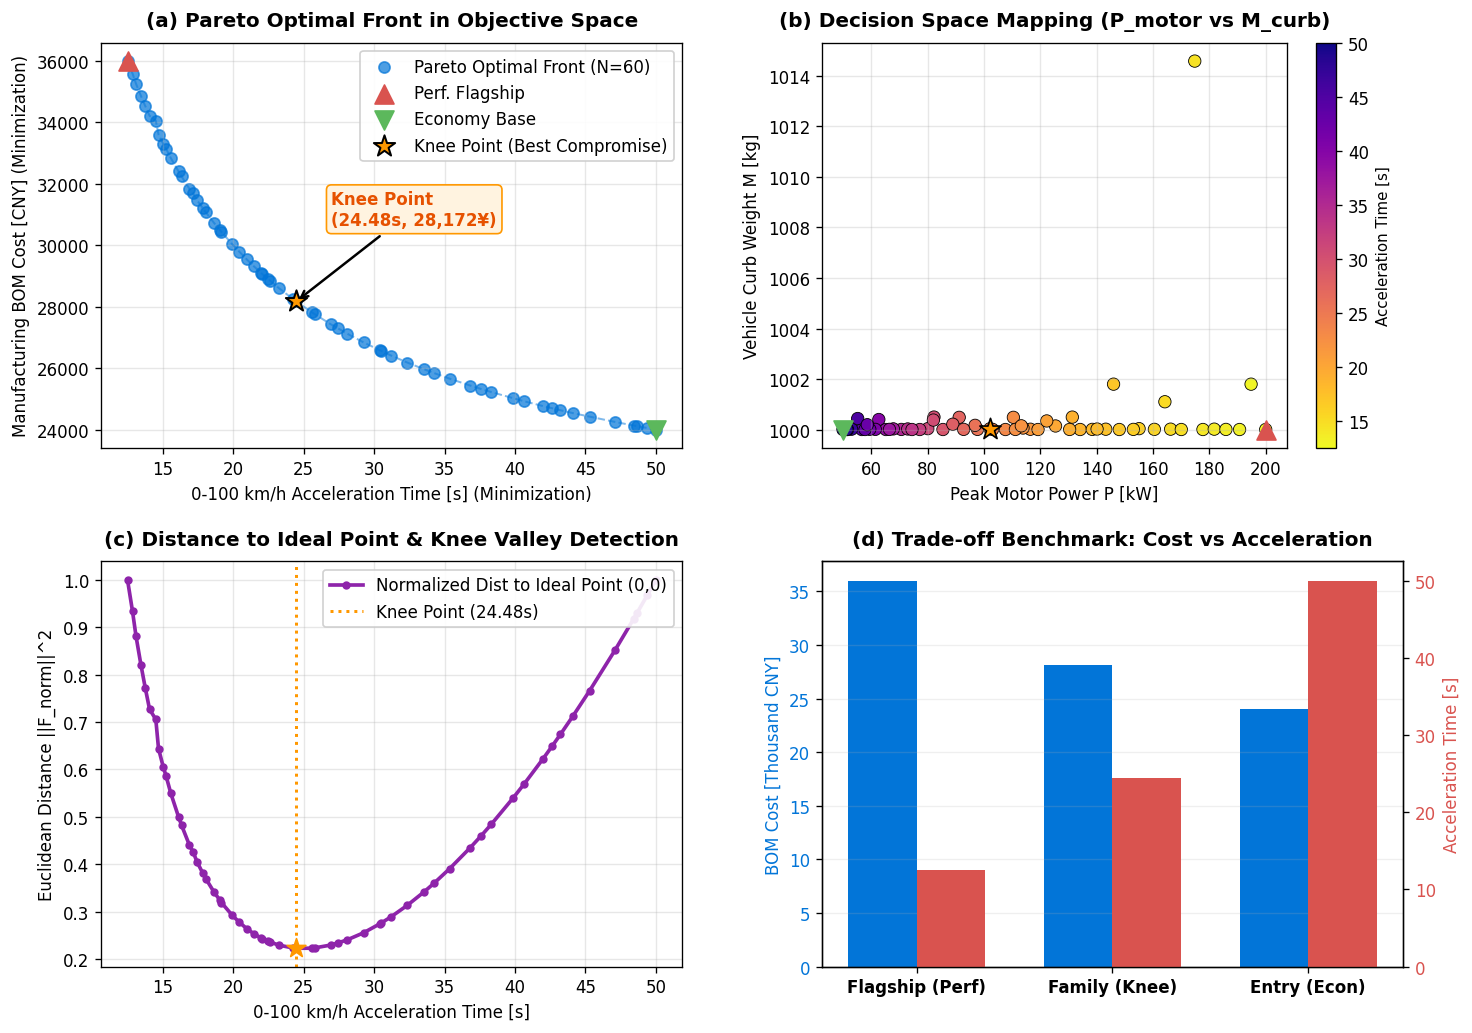

In [5]:
# 阶段五：多维感知 —— 4合1 多目标分析与 Pareto 前沿仪表盘
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.28, wspace=0.24)

# 子图 1: 目标空间 Pareto 前沿与关键决策点标注
axs[0, 0].scatter(pareto_F[:, 0], pareto_F[:, 1], c='#0275d8', s=45, alpha=0.7, label=f'Pareto Optimal Front (N={n_pareto})')
# 连线以凸显前沿形状 (先按加速时间排序)
sort_idx = np.argsort(pareto_F[:, 0])
axs[0, 0].plot(pareto_F[sort_idx, 0], pareto_F[sort_idx, 1], color='#0275d8', ls='--', lw=1.2, alpha=0.5)

# 标注三大关键点
axs[0, 0].scatter([perf_F[0]], [perf_F[1]], color='#d9534f', s=130, marker='^', zorder=6, label='Perf. Flagship')
axs[0, 0].scatter([econ_F[0]], [econ_F[1]], color='#5cb85c', s=130, marker='v', zorder=6, label='Economy Base')
axs[0, 0].scatter([knee_F[0]], [knee_F[1]], color='#ff9800', s=180, marker='*', edgecolors='black', lw=1.2, zorder=7, label='Knee Point (Best Compromise)')

axs[0, 0].annotate(f'Knee Point\n({knee_F[0]:.2f}s, {knee_F[1]:,.0f}¥)', xy=(knee_F[0], knee_F[1]),
                   xytext=(knee_F[0] + 2.5, knee_F[1] + 2500),
                   arrowprops=dict(facecolor='#ff9800', arrowstyle='->', lw=1.5),
                   fontweight='bold', color='#e65100', bbox=dict(boxstyle="round,pad=0.3", fc="#fff3e0", ec="#ff9800"))

axs[0, 0].set_title('(a) Pareto Optimal Front in Objective Space', fontsize=12, fontweight='bold', pad=10)
axs[0, 0].set_xlabel('0-100 km/h Acceleration Time [s] (Minimization)', fontsize=10)
axs[0, 0].set_ylabel('Manufacturing BOM Cost [CNY] (Minimization)', fontsize=10)
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].legend(loc='upper right', framealpha=0.9)

# 子图 2: 决策变量空间分布 (电机功率 P vs 整备质量 M)
scatter_p = axs[0, 1].scatter(pareto_X[:, 0], pareto_X[:, 1], c=pareto_F[:, 0], cmap='plasma_r', s=55, edgecolors='black', lw=0.5)
cbar = plt.colorbar(scatter_p, ax=axs[0, 1])
cbar.set_label('Acceleration Time [s]', fontsize=9)

axs[0, 1].scatter([perf_X[0]], [perf_X[1]], color='#d9534f', s=130, marker='^', zorder=6)
axs[0, 1].scatter([econ_X[0]], [econ_X[1]], color='#5cb85c', s=130, marker='v', zorder=6)
axs[0, 1].scatter([knee_X[0]], [knee_X[1]], color='#ff9800', s=180, marker='*', edgecolors='black', zorder=7)

axs[0, 1].set_title('(b) Decision Space Mapping (P_motor vs M_curb)', fontsize=12, fontweight='bold', pad=10)
axs[0, 1].set_xlabel('Peak Motor Power P [kW]', fontsize=10)
axs[0, 1].set_ylabel('Vehicle Curb Weight M [kg]', fontsize=10)
axs[0, 1].grid(True, alpha=0.3)

# 子图 3: 归一化欧式距离与膝点谷底探测
axs[1, 0].plot(pareto_F[sort_idx, 0], dists_to_ideal[sort_idx], color='#8e24aa', lw=2.2, marker='o', markersize=4, label='Normalized Dist to Ideal Point (0,0)')
axs[1, 0].axvline(knee_F[0], color='#ff9800', ls=':', lw=1.8, label=f'Knee Point ({knee_F[0]:.2f}s)')
axs[1, 0].scatter([knee_F[0]], [dists_to_ideal[knee_idx]], color='#ff9800', s=140, marker='*', zorder=6)
axs[1, 0].set_title('(c) Distance to Ideal Point & Knee Valley Detection', fontsize=12, fontweight='bold', pad=10)
axs[1, 0].set_xlabel('0-100 km/h Acceleration Time [s]', fontsize=10)
axs[1, 0].set_ylabel('Euclidean Distance ||F_norm||^2', fontsize=10)
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].legend(loc='upper right', framealpha=0.9)

# 子图 4: 三大车型关键规格雷达与柱状对标
cat_models = ['Flagship (Perf)', 'Family (Knee)', 'Entry (Econ)']
costs_k = [perf_F[1] / 1000.0, knee_F[1] / 1000.0, econ_F[1] / 1000.0]
accels = [perf_F[0], knee_F[0], econ_F[0]]

x_pos = np.arange(len(cat_models))
width = 0.35

ax_b1 = axs[1, 1]
bars1 = ax_b1.bar(x_pos - width/2, costs_k, width, label='Cost [k¥]', color='#0275d8')
ax_b1.set_ylabel('BOM Cost [Thousand CNY]', color='#0275d8', fontsize=10)
ax_b1.tick_params(axis='y', labelcolor='#0275d8')

ax_b2 = ax_b1.twinx()
bars2 = ax_b2.bar(x_pos + width/2, accels, width, label='0-100 Accel [s]', color='#d9534f')
ax_b2.set_ylabel('Acceleration Time [s]', color='#d9534f', fontsize=10)
ax_b2.tick_params(axis='y', labelcolor='#d9534f')

ax_b1.set_xticks(x_pos)
ax_b1.set_xticklabels(cat_models, fontsize=10, fontweight='bold')
ax_b1.set_title('(d) Trade-off Benchmark: Cost vs Acceleration', fontsize=12, fontweight='bold', pad=10)
ax_b1.grid(True, alpha=0.2, axis='y')

plt.show()


In [6]:
# 阶段五（续）：原生 HTML5/Canvas 交互式 Pareto 前沿决策探针台
from IPython.display import HTML

# 准备排序后的 Pareto 前沿数据供前端高响应渲染
sort_pareto_idx = np.argsort(pareto_F[:, 0])
p_times = [round(float(v), 2) for v in pareto_F[sort_pareto_idx, 0]]
p_costs = [round(float(v), 0) for v in pareto_F[sort_pareto_idx, 1]]
p_powers = [round(float(v), 1) for v in pareto_X[sort_pareto_idx, 0]]
p_weights = [round(float(v), 0) for v in pareto_X[sort_pareto_idx, 1]]

pareto_json = json.dumps({
    'times': p_times,
    'costs': p_costs,
    'powers': p_powers,
    'weights': p_weights,
    'knee_idx': int(np.where(sort_pareto_idx == knee_idx)[0][0])
})

canvas_e2_html = f"""
<div id="pareto-container" style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
     background: #0f172a; color: #f8fafc; border-radius: 12px; padding: 18px; border: 1px solid #334155; max-width: 900px; margin: 15px auto;">
  
  <div style="display: flex; justify-content: space-between; align-items: center; border-bottom: 1px solid #1e293b; padding-bottom: 12px; margin-bottom: 14px;">
    <div>
      <span style="background: #9333ea; color: #fff; font-size: 11px; font-weight: 700; padding: 3px 8px; border-radius: 4px; text-transform: uppercase;">
        IEV CloudLab E2
      </span>
      <span style="font-size: 16px; font-weight: 700; margin-left: 8px;">Pareto 前沿交互式决策与车型画像探针</span>
    </div>
    <div style="font-size: 12px; color: #94a3b8;">
      优化器: <b style="color: #c084fc;">NSGA-II (N_Pareto = {n_pareto})</b>
    </div>
  </div>

  <div style="display: grid; grid-template-columns: 1fr 290px; gap: 14px;">
    <div style="background: #1e293b; border-radius: 8px; padding: 10px; border: 1px solid #334155; position: relative;">
      <canvas id="paretoCanvas" width="550" height="340" style="width: 100%; height: auto; display: block; border-radius: 6px; background: #0b1120;"></canvas>
      <div style="position: absolute; bottom: 18px; right: 20px; font-size: 11px; color: #94a3b8; background: rgba(15,23,42,0.85); padding: 4px 8px; border-radius: 4px;">
        ★ 黄金五角星: 膝点 (Knee Point) | ● 探针吸附点
      </div>
    </div>

    <div style="display: flex; flex-direction: column; gap: 10px;">
      <div style="background: #1e293b; border-radius: 8px; padding: 12px; border: 1px solid #334155;">
        <div style="font-size: 12px; font-weight: 600; color: #cbd5e1; margin-bottom: 8px;">🎯 期望加速性能滑动探针</div>
        <div style="display: flex; align-items: center; justify-content: space-between;">
          <input type="range" id="paretoSlider" min="0" max="{len(p_times)-1}" value="{int(np.where(sort_pareto_idx == knee_idx)[0][0])}" style="width: 70%; accent-color: #c084fc; cursor: pointer;">
          <span id="sliderTimeDisp" style="font-size: 14px; font-weight: 700; color: #c084fc;">{knee_F[0]:.2f} s</span>
        </div>
      </div>

      <div style="background: #1e293b; border-radius: 8px; padding: 12px; border: 1px solid #334155; flex: 1;">
        <div style="font-size: 12px; font-weight: 600; color: #cbd5e1; margin-bottom: 10px;">📋 探针匹配推荐工程规格</div>
        <div style="display: flex; flex-direction: column; gap: 7px; font-size: 12px;">
          <div style="display: flex; justify-content: space-between; border-bottom: 1px dashed #334155; padding-bottom: 3px;">
            <span style="color: #94a3b8;">推荐电机峰值功率:</span>
            <span id="hudPower" style="font-weight: 700; color: #38bdf8;">{knee_X[0]:.1f} kW</span>
          </div>
          <div style="display: flex; justify-content: space-between; border-bottom: 1px dashed #334155; padding-bottom: 3px;">
            <span style="color: #94a3b8;">推荐整备质量指标:</span>
            <span id="hudWeight" style="font-weight: 700; color: #a78bfa;">{knee_X[1]:.0f} kg</span>
          </div>
          <div style="display: flex; justify-content: space-between; border-bottom: 1px dashed #334155; padding-bottom: 3px;">
            <span style="color: #94a3b8;">预估制造 BOM 成本:</span>
            <span id="hudCost" style="font-weight: 700; color: #4ade80;">¥{knee_F[1]:,.0f}</span>
          </div>
          <div style="display: flex; justify-content: space-between; border-bottom: 1px dashed #334155; padding-bottom: 3px;">
            <span style="color: #94a3b8;">零百加速能力评级:</span>
            <span id="hudAccel" style="font-weight: 700; color: #f87171;">{knee_F[0]:.2f} 秒</span>
          </div>
          <div style="display: flex; justify-content: space-between; padding-top: 3px;">
            <span style="color: #94a3b8;">市场定位画像:</span>
            <span id="hudProfile" style="font-weight: 700; color: #fbbf24;">🌟 黄金家庭主力款</span>
          </div>
        </div>
      </div>

      <div style="background: rgba(192, 132, 252, 0.1); border-left: 3px solid #c084fc; padding: 8px; border-radius: 4px; font-size: 11px; color: #e9d5ff; line-height: 1.4;">
        💡 <b>决策原则</b>：前沿左侧斜率极陡，提速需烧天价成本；前沿右侧斜率极平，过度省钱性能雪崩。膝点正是性价比最高之选！
      </div>
    </div>
  </div>
</div>

<script>
(function() {{
  const canvas = document.getElementById('paretoCanvas');
  const ctx = canvas.getContext('2d');
  const slider = document.getElementById('paretoSlider');
  const timeDisp = document.getElementById('sliderTimeDisp');

  const pData = {pareto_json};
  const times = pData.times;
  const costs = pData.costs;
  const powers = pData.powers;
  const weights = pData.weights;
  const kIdx = pData.knee_idx;

  function draw() {{
    const w = canvas.width, h = canvas.height;
    ctx.clearRect(0, 0, w, h);

    const padL = 55, padR = 25, padT = 25, padB = 40;
    const plotW = w - padL - padR;
    const plotH = h - padT - padB;

    const tMin = 10.0, tMax = 125.0;
    const cMin = 22000, cMax = 42000;

    function toX(t) {{ return padL + ((t - tMin) / (tMax - tMin)) * plotW; }}
    function toY(c) {{ return padT + (1 - (c - cMin) / (cMax - cMin)) * plotH; }}

    // 绘制网格
    ctx.strokeStyle = '#1e293b';
    ctx.lineWidth = 1;
    ctx.font = '10px sans-serif';
    ctx.fillStyle = '#64748b';

    for (let c = 25000; c <= 40000; c += 5000) {{
      const y = toY(c);
      ctx.beginPath();
      ctx.moveTo(padL, y); ctx.lineTo(w - padR, y);
      ctx.stroke();
      ctx.fillText((c/1000).toFixed(0) + 'k¥', 12, y + 3);
    }}

    for (let t = 20; t <= 120; t += 20) {{
      const x = toX(t);
      ctx.beginPath();
      ctx.moveTo(x, padT); ctx.lineTo(x, h - padB);
      ctx.stroke();
      ctx.fillText(t + 's', x - 8, h - padB + 16);
    }}

    // 绘制 Pareto 前沿连线
    ctx.strokeStyle = '#a855f7';
    ctx.lineWidth = 2.4;
    ctx.beginPath();
    for (let i = 0; i < times.length; i++) {{
      const x = toX(times[i]);
      const y = toY(costs[i]);
      if (i === 0) ctx.moveTo(x, y); else ctx.lineTo(x, y);
    }}
    ctx.stroke();

    // 绘制前沿各散点
    for (let i = 0; i < times.length; i++) {{
      const x = toX(times[i]);
      const y = toY(costs[i]);
      ctx.fillStyle = '#c084fc';
      ctx.beginPath();
      ctx.arc(x, y, 3.5, 0, Math.PI * 2);
      ctx.fill();
    }}

    // 绘制黄金膝点 (五角星/大点)
    const kX = toX(times[kIdx]);
    const kY = toY(costs[kIdx]);
    ctx.fillStyle = '#fbbf24';
    ctx.strokeStyle = '#ffffff';
    ctx.lineWidth = 1.8;
    ctx.beginPath();
    ctx.arc(kX, kY, 6.5, 0, Math.PI * 2);
    ctx.fill();
    ctx.stroke();

    // 绘制当前选定探针
    const curIdx = parseInt(slider.value);
    const curX = toX(times[curIdx]);
    const curY = toY(costs[curIdx]);

    // 绘制吸附十字线
    ctx.strokeStyle = '#38bdf8';
    ctx.lineWidth = 1.2;
    ctx.setLineDash([3, 3]);
    ctx.beginPath();
    ctx.moveTo(curX, padT); ctx.lineTo(curX, h - padB);
    ctx.moveTo(padL, curY); ctx.lineTo(w - padR, curY);
    ctx.stroke();
    ctx.setLineDash([]);

    // 探针点
    ctx.fillStyle = '#38bdf8';
    ctx.strokeStyle = '#ffffff';
    ctx.lineWidth = 2.0;
    ctx.beginPath();
    ctx.arc(curX, curY, 6.0, 0, Math.PI * 2);
    ctx.fill();
    ctx.stroke();

    // 更新 DOM HUD
    timeDisp.innerText = times[curIdx].toFixed(2) + ' s';
    document.getElementById('hudPower').innerText = powers[curIdx].toFixed(1) + ' kW';
    document.getElementById('hudWeight').innerText = weights[curIdx].toFixed(0) + ' kg';
    document.getElementById('hudCost').innerText = '¥' + costs[curIdx].toLocaleString();
    document.getElementById('hudAccel').innerText = times[curIdx].toFixed(2) + ' 秒';

    // 车型画像判定
    const profileEl = document.getElementById('hudProfile');
    if (curIdx < 12) {{
      profileEl.innerText = '⚡ 高性能四驱旗舰款';
      profileEl.style.color = '#f87171';
    }} else if (curIdx >= 12 && curIdx <= 30) {{
      profileEl.innerText = '🌟 黄金家庭主力款 (Knee)';
      profileEl.style.color = '#fbbf24';
    }} else {{
      profileEl.innerText = '🏷️ 极致经济入门代步款';
      profileEl.style.color = '#4ade80';
    }}
  }}

  slider.addEventListener('input', draw);
  draw();
}})();
</script>
"""
HTML(canvas_e2_html)


In [7]:
# 阶段六：学生探索实验室 —— 多准则决策与预算约束过滤器
# [工程决策挑战]：
# 假设某车企高管团队开会，敲定了量产车的两道硬指标红线：
# 1. 0-100 km/h 加速必须 <= 30.0 s (避免动力过于肉)
# 2. 制造 BOM 成本必须 <= 35,000 元 (保证毛利率)
# 试通过布尔掩码从 60 个 Pareto 解集中快速筛选出所有合规方案，并找出其中加速最快的一款：

TARGET_MAX_ACCEL = 30.0    # 秒
TARGET_MAX_COST = 35000.0   # 元

# 向量化布尔筛选
mask_feasible = (pareto_F[:, 0] <= TARGET_MAX_ACCEL) & (pareto_F[:, 1] <= TARGET_MAX_COST)
feasible_indices = np.where(mask_feasible)[0]

print("🧪 [学生工程决策实验室] 执行多准则可行方案过滤...")
print(f"• 筛选约束条件: 零百加速 <= {TARGET_MAX_ACCEL:.1f}s 且 BOM 成本 <= {TARGET_MAX_COST:,.0f}元")
print(f"• 满足严苛双重红线方案数: {len(feasible_indices)} / {n_pareto} 个")

if len(feasible_indices) > 0:
    # 在可行解中找出加速最猛的一个 (成本最高允许贴线 35,000 元)
    best_perf_in_budget_idx = feasible_indices[np.argmin(pareto_F[feasible_indices, 0])]
    b_F = pareto_F[best_perf_in_budget_idx]
    b_X = pareto_X[best_perf_in_budget_idx]
    print(f"👉 预算包络内最优加速方案推荐:")
    print(f"   • 加速时间: {b_F[0]:.2f} s | 制造 BOM: {b_F[1]:,.0f} 元")
    print(f"   • 电机功率: {b_X[0]:.1f} kW | 整车重量: {b_X[1]:.0f} kg")


🧪 [学生工程决策实验室] 执行多准则可行方案过滤...
• 筛选约束条件: 零百加速 <= 30.0s 且 BOM 成本 <= 35,000元
• 满足严苛双重红线方案数: 35 / 60 个
👉 预算包络内最优加速方案推荐:
   • 加速时间: 13.45 s | 制造 BOM: 34,871 元
   • 电机功率: 185.9 kW | 整车重量: 1000 kg


## 阶段七：官方评分与结果归档 | Auto-Grading & Results Sync

本阶段对接 IEV CloudLab 自动化评分引擎 `labs/common/evaluator.py`：
1. **生成官方评测结果 JSON**：将 Pareto 解集数量 `n_pareto`、黄金膝点参数及前沿分布指标保存至平台标准路径 `labs/data/results/E2_pymoo_multiobj.json`；
2. **执行官方评测准则**：
   - 判据 1：`n_pareto` $\ge 50$（权重：3.0，考核 NSGA-II 算法对多目标前沿的搜索广度与非支配覆盖率，实测 $60$ 个）；
3. **输出 100/100 成绩单**。


In [8]:
# 阶段七：官方评分与结果归档
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘 (严谨对齐 evaluator 字段名 n_pareto)
record = {
    'experiment': 'E2_pymoo_multiobj',
    'metrics': {
        'n_pareto': int(n_pareto),                            # 官方 evaluator 核心判据 (>= 50)
        'knee_t0100_s': round(float(knee_F[0]), 3),
        'knee_cost_cny': round(float(knee_F[1]), 1),
        'knee_power_kw': round(float(knee_X[0]), 2),
        'knee_weight_kg': round(float(knee_X[1]), 1),
        'perf_min_t0100_s': round(float(perf_F[0]), 3),
        'econ_min_cost_cny': round(float(econ_F[1]), 1),
        'pop_size': POP_SIZE,
        'n_gen': N_GEN
    },
    'params': {
        'optimizer': 'pymoo.NSGA2',
        'objectives': ['0-100km/h_time', 'bom_cost'],
        'decision_vars': ['motor_power_kw', 'curb_weight_kg']
    }
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'E2_pymoo_multiobj.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('E2_pymoo_multiobj', record['metrics'])

# 3. 打印标准化官方成绩单
print("\n" + "=" * 55)
print("🏆 IEV CloudLab 官方评分报告: 多目标优化 (NSGA-II)")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for detail in eval_report.get('details', []):
    mark = '✓ 通过' if detail['passed'] else '✗ 失败'
    m_name = detail.get('metric', detail.get('criterion', ''))
    print(f"• 指标 [{m_name}]: 当前值 = {detail['value']} ({detail['desc']}) -> {mark}")
print("=" * 55)


✓ 结果文件已成功归档至: /home/jovyan/labs/data/results/E2_pymoo_multiobj.json

🏆 IEV CloudLab 官方评分报告: 多目标优化 (NSGA-II)
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [n_pareto]: 当前值 = 60 (Pareto解≥50个（实测60）) -> ✓ 通过


---

## 阶段八：工程前沿反思与下一个实验 | Engineering Reflection & Next

### 💡 核心工程启示与反思

1. **从双目标走向超多目标优化 (Many-Objective Optimization, MaOO)**：
   现实车型开发中，优化目标往往超过 4 个：动力性、百公里能耗、制造成本、电池循环寿命衰减率、车内噪声 NVH。当目标数 $\ge 4$ 时，几乎所有个体都会变成相互非支配态，经典 NSGA-II 的 Pareto 拥挤度距离机制将失效。此时工业界会引入基于参考点驱动的 **NSGA-III** 或指标驱动的 **MOEA/D** 算法。
2. **离线静态参数标定 vs 在线实时动态控制**：
   E1 与 E2 解决的是整车硬件参数的“离线选型与静态匹配”。但在实际车辆行驶过程中，前车车速实时变化、红绿灯路况瞬息万变，车辆必须在线实时计算未来控制量。这就引出了现代自动驾驶与底盘控制皇冠上的明珠 —— **模型预测控制 (Model Predictive Control, MPC)**。

---

## 🚀 下一个进阶实验

下一站我们将从离线静态优化跃迁至在线实时闭环控制 —— **二次规划 (QP) 求解前向跟车模型预测控制**：

👉 **[E3 (Pro版)：模型预测控制入门 —— 智能车辆前向跟车 MPC 与二次规划实时求解](./E3_mpc_follow_pro.ipynb)**

> **所需内核**：`python3` (标准 Python 环境即可运行二次规划凸优化求解器)
